Below we import packages.

In [21]:
# %% Cell 1: Imports and Setup
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import time
import warnings
warnings.filterwarnings('ignore')


# Plot style
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'legend.fontsize':10,
    'figure.figsize': (10, 6),
    'lines.linewidth': 1.5,
})
print("Imports done.")

Imports done.


Below we load Mnist and prepare train and test datasets.

In [22]:
# %% Cell 2: Load and preprocess MNIST (binary: digits 0 vs 1)
print("Loading MNIST...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X_all, y_all = mnist.data, mnist.target.astype(int)

# Binary subset: digits 0 vs 1
mask = (y_all == 0) | (y_all == 1)
X_bin = X_all[mask]
y_bin = y_all[mask].astype(float)  # 0 or 1

# Subsample for speed (use N training samples)
N_train = 2000
N_test = 500

X_train, X_test, y_train, y_test = train_test_split(
    X_bin, y_bin, train_size=N_train, test_size=N_test, 
    random_state=42, stratify=y_bin[:len(X_bin)]
)

# Standardise features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")
print(f"Input dimension d = {X_train.shape[1]}")

Loading MNIST...
Training set: (2000, 784), Test set: (500, 784)
Input dimension d = 784


Below we implement the Neural Network used in the numerical example.

In [23]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))
 
def relu(z):
    return np.maximum(0, z)
 
def relu_grad(z):
    return (z > 0).astype(float)
 
class TwoLayerNet:
    """
    Two-layer fully connected network for binary classification.
    Architecture: input (d) -> hidden (h) with ReLU -> output (1) with sigmoid
    Parameters stored as a single flat vector theta for ZO compatibility.
    """
    def __init__(self, d, h):
        self.d = d
        self.h = h
        self.n_params = d * h + h + h * 1 + 1  # W1, b1, W2, b2
        
    def _unpack(self, theta):
        """Unpack flat parameter vector into weight matrices and biases."""
        idx = 0
        W1 = theta[idx:idx + self.d * self.h].reshape(self.d, self.h)
        idx += self.d * self.h
        b1 = theta[idx:idx + self.h]
        idx += self.h
        W2 = theta[idx:idx + self.h].reshape(self.h, 1)
        idx += self.h
        b2 = theta[idx:idx + 1]
        return W1, b1, W2, b2
    
    def forward(self, X, theta):
        """Forward pass. Returns predictions and cached activations."""
        W1, b1, W2, b2 = self._unpack(theta)
        z1 = X @ W1 + b1          # (N, h)
        a1 = relu(z1)              # (N, h)
        z2 = a1 @ W2 + b2         # (N, 1)
        a2 = sigmoid(z2).ravel()   # (N,)
        cache = (X, z1, a1, z2, W1, b1, W2, b2)
        return a2, cache
    
    def loss(self, X, y, theta, lam):
        """Logistic loss + L2 regularisation."""
        pred, _ = self.forward(X, theta)
        pred = np.clip(pred, 1e-12, 1 - 1e-12)
        data_loss = -np.mean(y * np.log(pred) + (1 - y) * np.log(1 - pred))
        reg_loss = lam * np.sum(theta**2)
        return data_loss + reg_loss
    
    def gradient(self, X, y, theta, lam):
        """Exact gradient via backpropagation."""
        N = X.shape[0]
        pred, cache = self.forward(X, theta)
        X_c, z1, a1, z2, W1, b1, W2, b2 = cache
        
        # Output layer gradient
        dz2 = (pred - y).reshape(-1, 1) / N  # (N, 1)
        dW2 = a1.T @ dz2                      # (h, 1)
        db2 = np.sum(dz2, axis=0)              # (1,)
        
        # Hidden layer gradient
        da1 = dz2 @ W2.T                       # (N, h)
        dz1 = da1 * relu_grad(z1)              # (N, h)
        dW1 = X_c.T @ dz1                      # (d, h)
        db1 = np.sum(dz1, axis=0)              # (h,)
        
        # Pack gradient + regularisation
        grad = np.concatenate([dW1.ravel(), db1, dW2.ravel(), db2])
        grad += 2 * lam * theta
        return grad
    
    def init_params(self, scale=0.01):
        """Xavier-like initialisation."""
        theta = np.random.randn(self.n_params) * scale
        return theta
 
# Quick test
net_test = TwoLayerNet(d=X_train.shape[1], h=64)
theta_test = net_test.init_params()
print(f"Test network: d={net_test.d}, h={net_test.h}, n_params={net_test.n_params}")
print(f"Test loss: {net_test.loss(X_train, y_train, theta_test, lam=1e-4):.4f}")
 
# Gradient check (optional)
grad_exact = net_test.gradient(X_train, y_train, theta_test, lam=1e-4)
eps_check = 1e-5
grad_fd = np.zeros_like(theta_test)
for i in range(min(20, len(theta_test))):
    e_i = np.zeros_like(theta_test)
    e_i[i] = eps_check
    grad_fd[i] = (net_test.loss(X_train, y_train, theta_test + e_i, lam=1e-4) 
                  - net_test.loss(X_train, y_train, theta_test - e_i, lam=1e-4)) / (2 * eps_check)
rel_err = np.linalg.norm(grad_exact[:20] - grad_fd[:20]) / (np.linalg.norm(grad_exact[:20]) + 1e-12)
print(f"Gradient check (first 20 coords) relative error: {rel_err:.2e}")

Test network: d=784, h=64, n_params=50305
Test loss: 0.6916
Gradient check (first 20 coords) relative error: 1.35e-06


Below we implement the optiisation methods.

In [24]:
def zo_gradient_estimate(loss_fn, theta, mu, t):
    """
    Two-point ZO gradient estimate with mini-batch of t directions.
    g_mu = (1/t) sum_{j=1}^t [ (f(theta + mu*u_j) - f(theta)) / mu ] * u_j
    """
    n = len(theta)
    g = np.zeros(n)
    f_base = loss_fn(theta)
    for _ in range(t):
        u = np.random.randn(n)
        f_pert = loss_fn(theta + mu * u)
        g += ((f_pert - f_base) / mu) * u
    return g / t
 
 
def run_gd(net, X, y, lam, theta0, alpha, n_iters, zo=False, mu=1e-4, t=1):
    """Gradient Descent (FO or ZO)."""
    theta = theta0.copy()
    losses = []
    loss_fn = lambda th: net.loss(X, y, th, lam)
    
    for k in range(n_iters):
        losses.append(loss_fn(theta))
        if zo:
            grad = zo_gradient_estimate(loss_fn, theta, mu, t)
        else:
            grad = net.gradient(X, y, theta, lam)
        theta = theta - alpha * grad
    losses.append(loss_fn(theta))
    return theta, np.array(losses)
 
 
def run_hb(net, X, y, lam, theta0, alpha1, alpha2, n_iters, zo=False, mu=1e-4, t=1):
    """Heavy Ball method (FO or ZO)."""
    theta = theta0.copy()
    theta_prev = theta0.copy()
    losses = []
    loss_fn = lambda th: net.loss(X, y, th, lam)
    
    for k in range(n_iters):
        losses.append(loss_fn(theta))
        if zo:
            grad = zo_gradient_estimate(loss_fn, theta, mu, t)
        else:
            grad = net.gradient(X, y, theta, lam)
        theta_new = theta - alpha1 * grad + alpha2 * (theta - theta_prev)
        theta_prev = theta.copy()
        theta = theta_new
    losses.append(loss_fn(theta))
    return theta, np.array(losses)
 
 
def run_nag(net, X, y, lam, theta0, alpha1, alpha2, n_iters, zo=False, mu=1e-4, t=1):
    """Nesterov's Accelerated Gradient (FO or ZO)."""
    theta = theta0.copy()
    theta_prev = theta0.copy()
    losses = []
    loss_fn = lambda th: net.loss(X, y, th, lam)
    
    for k in range(n_iters):
        losses.append(loss_fn(theta))
        # Lookahead point
        theta_look = theta + alpha2 * (theta - theta_prev)
        if zo:
            grad = zo_gradient_estimate(loss_fn, theta_look, mu, t)
        else:
            grad = net.gradient(X, y, theta_look, lam)
        theta_new = theta_look - alpha1 * grad
        theta_prev = theta.copy()
        theta = theta_new
    losses.append(loss_fn(theta))
    return theta, np.array(losses)
 
print("Optimizers defined.")
d = X_train.shape[1]

Optimizers defined.


Below we train and test the Neural network with 128 hidden neurons using 6 different optimisers. ZO and FO versions of GD, NAG, and HB.

In [5]:
print("=" * 60)
print("Experiment 1: FO vs ZO convergence comparison")
print("=" * 60)
 
# Network setup
h = 128
d = X_train.shape[1]
net = TwoLayerNet(d=d, h=h)
n_params = net.n_params
print(f"Network: d={d}, h={h}, n_params={n_params}")
 
# Shared parameters
lam = 1e-2       # L2 regularisation
n_iters = 1000    # Number of iterations
n_zo_runs = 2    # Number of ZO runs to average
 
# Algorithm-specific parameters (tuned to be in the admissible range)
alpha_gd = 1e-3
alpha1_hb = 1e-3
alpha2_hb = 5e-4
alpha1_nag = 1e-3
alpha2_nag = 5e-4
 
# ZO parameters
mu = 1e-7
t_batch = 7  # Mini-batch size for ZO
 
# Shared initial point
theta0 = net.init_params(scale=0.01)
 
# --- FO runs ---
print("\nRunning FO-GD...")
t0 = time.time()
theta_final_gd, losses_gd = run_gd(net, X_train, y_train, lam, theta0, alpha_gd, n_iters)
print(f"  Done in {time.time()-t0:.1f}s, final loss: {losses_gd[-1]:.6f}")
 
print("Running FO-HB...")
t0 = time.time()
theta_final_hb, losses_hb = run_hb(net, X_train, y_train, lam, theta0, alpha1_hb, alpha2_hb, n_iters)
print(f"  Done in {time.time()-t0:.1f}s, final loss: {losses_hb[-1]:.6f}")
 
print("Running FO-NAG...")
t0 = time.time()
theta_final_nag, losses_nag = run_nag(net, X_train, y_train, lam, theta0, alpha1_nag, alpha2_nag, n_iters)
print(f"  Done in {time.time()-t0:.1f}s, final loss: {losses_nag[-1]:.6f}")
 
# --- ZO runs (averaged) ---
print(f"\nRunning ZO-GD (mu={mu}, t={t_batch}, {n_zo_runs} runs)...")
t0 = time.time()
zo_gd_all = []
best_zo_gd_loss = np.inf
for run in range(n_zo_runs):
    # np.random.seed(100 + run)
    theta_zo, losses = run_gd(net, X_train, y_train, lam, theta0, alpha_gd, n_iters, 
                       zo=True, mu=mu, t=t_batch)
    zo_gd_all.append(losses)
    if losses[-1] < best_zo_gd_loss:
        best_zo_gd_loss = losses[-1]
        theta_final_zo_gd = theta_zo.copy()
losses_zo_gd = np.mean(zo_gd_all, axis=0)
print(f"  Done in {time.time()-t0:.1f}s, final loss (avg): {losses_zo_gd[-1]:.6f}, best: {best_zo_gd_loss:.6f}")

print(f"Running ZO-HB (mu={mu}, t={t_batch}, {n_zo_runs} runs)...")
t0 = time.time()
zo_hb_all = []
best_zo_hb_loss = np.inf
for run in range(n_zo_runs):
    # np.random.seed(200 + run)
    theta_zo, losses = run_hb(net, X_train, y_train, lam, theta0, alpha1_hb, alpha2_hb, n_iters, 
                       zo=True, mu=mu, t=t_batch)
    zo_hb_all.append(losses)
    if losses[-1] < best_zo_hb_loss:
        best_zo_hb_loss = losses[-1]
        theta_final_zo_hb = theta_zo.copy()
losses_zo_hb = np.mean(zo_hb_all, axis=0)
print(f"  Done in {time.time()-t0:.1f}s, final loss (avg): {losses_zo_hb[-1]:.6f}, best: {best_zo_hb_loss:.6f}")

print(f"Running ZO-NAG (mu={mu}, t={t_batch}, {n_zo_runs} runs)...")
t0 = time.time()
zo_nag_all = []
best_zo_nag_loss = np.inf
for run in range(n_zo_runs):
    # np.random.seed(300 + run)
    theta_zo, losses = run_nag(net, X_train, y_train, lam, theta0, alpha1_nag, alpha2_nag, n_iters, 
                        zo=True, mu=mu, t=t_batch)
    zo_nag_all.append(losses)
    if losses[-1] < best_zo_nag_loss:
        best_zo_nag_loss = losses[-1]
        theta_final_zo_nag = theta_zo.copy()
losses_zo_nag = np.mean(zo_nag_all, axis=0)
print(f"  Done in {time.time()-t0:.1f}s, final loss (avg): {losses_zo_nag[-1]:.6f}, best: {best_zo_nag_loss:.6f}")
 

Experiment 1: FO vs ZO convergence comparison
Network: d=784, h=128, n_params=100609

Running FO-GD...
  Done in 38.9s, final loss: 0.364513
Running FO-HB...
  Done in 39.3s, final loss: 0.364270
Running FO-NAG...
  Done in 40.7s, final loss: 0.364270

Running ZO-GD (mu=1e-07, t=7, 2 runs)...
  Done in 307.9s, final loss (avg): 0.416013, best: 0.408211
Running ZO-HB (mu=1e-07, t=7, 2 runs)...
  Done in 333.9s, final loss (avg): 0.424308, best: 0.419995
Running ZO-NAG (mu=1e-07, t=7, 2 runs)...
  Done in 326.5s, final loss (avg): 0.413881, best: 0.412375


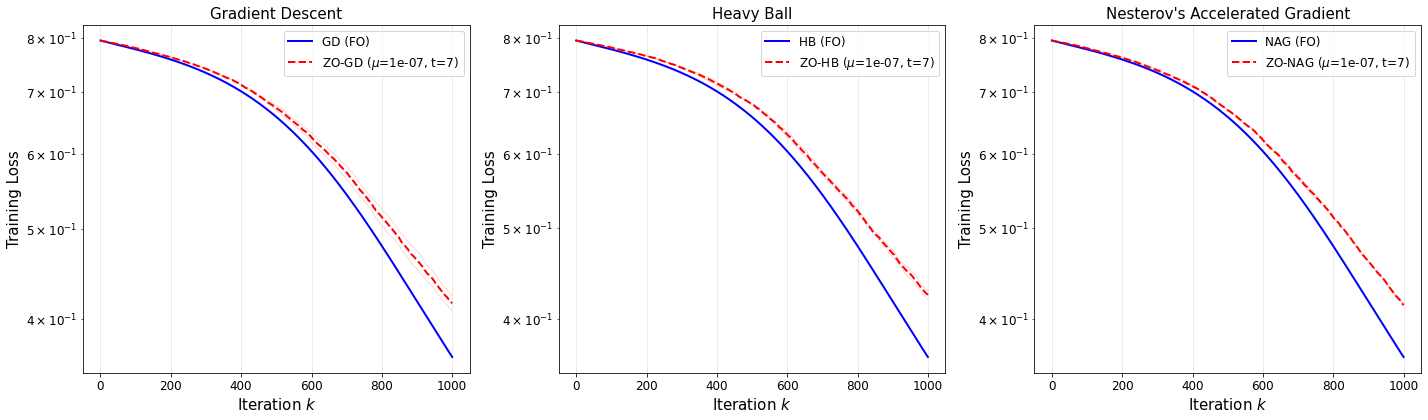

Plot saved: nn_fo_vs_zo_convergence.pdf


In [28]:
# %% Cell 6: Plot Experiment 1
 
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
 
iters = np.arange(len(losses_gd))
 
# GD plot
axes[0].semilogy(iters, losses_gd, 'b-', label='GD (FO)', linewidth=2)
axes[0].semilogy(iters, losses_zo_gd, 'r--', label=f'ZO-GD ($\\mu$={mu}, t={t_batch})', linewidth=2)
for run_losses in zo_gd_all:
    axes[0].semilogy(iters, run_losses, 'r-', alpha=0.3, linewidth=0.5)
axes[0].set_xlabel('Iteration $k$',fontsize=15)
axes[0].set_ylabel('Training Loss',fontsize=15)
axes[0].set_title('Gradient Descent',fontsize=15)
axes[0].legend(fontsize=12)
axes[0].grid(True, alpha=0.3)
 
# HB plot
axes[1].semilogy(iters, losses_hb, 'b-', label='HB (FO)', linewidth=2)
axes[1].semilogy(iters, losses_zo_hb, 'r--', label=f'ZO-HB ($\\mu$={mu}, t={t_batch})', linewidth=2)
for run_losses in zo_hb_all:
    axes[1].semilogy(iters, run_losses, 'r-', alpha=0.3, linewidth=0.5)
axes[1].set_xlabel('Iteration $k$',fontsize=15)
axes[1].set_ylabel('Training Loss',fontsize=15)
axes[1].set_title('Heavy Ball',fontsize=15)
axes[1].legend(fontsize=12)
axes[1].grid(True, alpha=0.3)
 
# NAG plot
axes[2].semilogy(iters, losses_nag, 'b-', label='NAG (FO)', linewidth=2)
axes[2].semilogy(iters, losses_zo_nag, 'r--', label=f'ZO-NAG ($\\mu$={mu}, t={t_batch})', linewidth=2)
for run_losses in zo_nag_all:
    axes[2].semilogy(iters, run_losses, 'r-', alpha=0.3, linewidth=0.5)
axes[2].set_xlabel('Iteration $k$',fontsize=15)
axes[2].set_ylabel('Training Loss',fontsize=15)
axes[2].set_title("Nesterov's Accelerated Gradient",fontsize=15)
axes[2].legend(fontsize=12)
axes[2].grid(True, alpha=0.3)
 
# plt.suptitle(f'FO vs ZO Convergence (n={n_params:,}, $\\lambda$={lam})', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('nn_fo_vs_zo_convergence.pdf', bbox_inches='tight', dpi=300)
plt.show()
print("Plot saved: nn_fo_vs_zo_convergence.pdf")

In [ ]:
def predict_accuracy(net, X, y, theta):
    pred, _ = net.forward(X, theta)
    labels = (pred >= 0.5).astype(float)
    return np.mean(labels == y) * 100

# Print results
print("=" * 65)
print(f"{'Method':<12} {'Train Acc (%)':>14} {'Test Acc (%)':>14} {'Final Loss':>12}")
print("-" * 65)
for name, theta in [('GD', theta_final_gd), ('ZO-GD', theta_final_zo_gd),
                     ('HB', theta_final_hb), ('ZO-HB', theta_final_zo_hb),
                     ('NAG', theta_final_nag), ('ZO-NAG', theta_final_zo_nag)]:
    train_acc = predict_accuracy(net, X_train, y_train, theta)
    test_acc = predict_accuracy(net, X_test, y_test, theta)
    loss = net.loss(X_train, y_train, theta, lam)
    print(f"{name:<12} {train_acc:>13.2f}% {test_acc:>13.2f}% {loss:>12.6f}")
print("=" * 65)

In [8]:
# Initial accuracy (before any training)
train_acc_init = predict_accuracy(net, X_train, y_train, theta0)
test_acc_init = predict_accuracy(net, X_test, y_test, theta0)
loss_init = net.loss(X_train, y_train, theta0, lam)
print(f"Initial:  Train Acc = {train_acc_init:.2f}%,  Test Acc = {test_acc_init:.2f}%,  Loss = {loss_init:.6f}")

Initial:  Train Acc = 53.60%,  Test Acc = 54.20%,  Loss = 0.794130


Below we implement a parameter sensevity experiment for ZO-GD.

In [15]:
# %% Cell 7: Experiment 2 - Parameter sensitivity for ZO-GD on neural network
# Vary mu, alpha, t individually (analogous to the quadratic experiments)
 
print("=" * 60)
print("Experiment 2: Parameter sensitivity (ZO-GD)")
print("=" * 60)
 
n_iters_param = 100
n_zo_runs_param = 2
 
# --- Vary step size alpha ---
print("\n--- Varying step size alpha ---")
alphas = [2e-3, 1e-3, 5e-4, 1e-4]
mu_fixed = 1e-7
t_fixed = 5
 
results_alpha = {}
# FO baseline with smallest alpha (for reference)
for alpha_val in alphas:
    print(f"  alpha={alpha_val}...")
    _, fo_loss = run_gd(net, X_train, y_train, lam, theta0, alpha_val, n_iters_param)
    zo_losses_runs = []
    for run in range(n_zo_runs_param):
        # np.random.seed(400 + run)
        _, zo_loss = run_gd(net, X_train, y_train, lam, theta0, alpha_val, n_iters_param,
                            zo=True, mu=mu_fixed, t=t_fixed)
        zo_losses_runs.append(zo_loss)
    results_alpha[alpha_val] = {
        'fo': fo_loss,
        'zo_mean': np.mean(zo_losses_runs, axis=0),
        'zo_all': zo_losses_runs
    }
 
# --- Vary smoothing parameter mu ---
print("\n--- Varying smoothing parameter mu ---")
mus = [5e-3, 1e-3, 1e-6, 1e-7]
alpha_fixed = 1e-3
t_fixed_mu = 5
 
_, fo_loss_base = run_gd(net, X_train, y_train, lam, theta0, alpha_fixed, n_iters_param)
 
results_mu = {}
for mu_val in mus:
    print(f"  mu={mu_val}...")
    zo_losses_runs = []
    for run in range(n_zo_runs_param):
        # np.random.seed(500 + run)
        _, zo_loss = run_gd(net, X_train, y_train, lam, theta0, alpha_fixed, n_iters_param,
                            zo=True, mu=mu_val, t=t_fixed_mu)
        zo_losses_runs.append(zo_loss)
    results_mu[mu_val] = {
        'zo_mean': np.mean(zo_losses_runs, axis=0),
        'zo_all': zo_losses_runs
    }
 
# --- Vary mini-batch size t ---
print("\n--- Varying mini-batch size t ---")
t_vals = [1, 3, 5, 10]
alpha_fixed_t = 1e-3
mu_fixed_t = 1e-7
 
results_t = {}
for t_val in t_vals:
    print(f"  t={t_val}...")
    zo_losses_runs = []
    for run in range(n_zo_runs_param):
        # np.random.seed(600 + run)
        _, zo_loss = run_gd(net, X_train, y_train, lam, theta0, alpha_fixed_t, n_iters_param,
                            zo=True, mu=mu_fixed_t, t=t_val)
        zo_losses_runs.append(zo_loss)
    results_t[t_val] = {
        'zo_mean': np.mean(zo_losses_runs, axis=0),
        'zo_all': zo_losses_runs
    }
 
print("Parameter sensitivity runs complete.")

Experiment 2: Parameter sensitivity (ZO-GD)

--- Varying step size alpha ---
  alpha=0.002...
  alpha=0.001...
  alpha=0.0005...
  alpha=0.0001...

--- Varying smoothing parameter mu ---
  mu=0.005...
  mu=0.001...
  mu=1e-06...
  mu=1e-07...

--- Varying mini-batch size t ---
  t=1...
  t=3...
  t=5...
  t=10...
Parameter sensitivity runs complete.


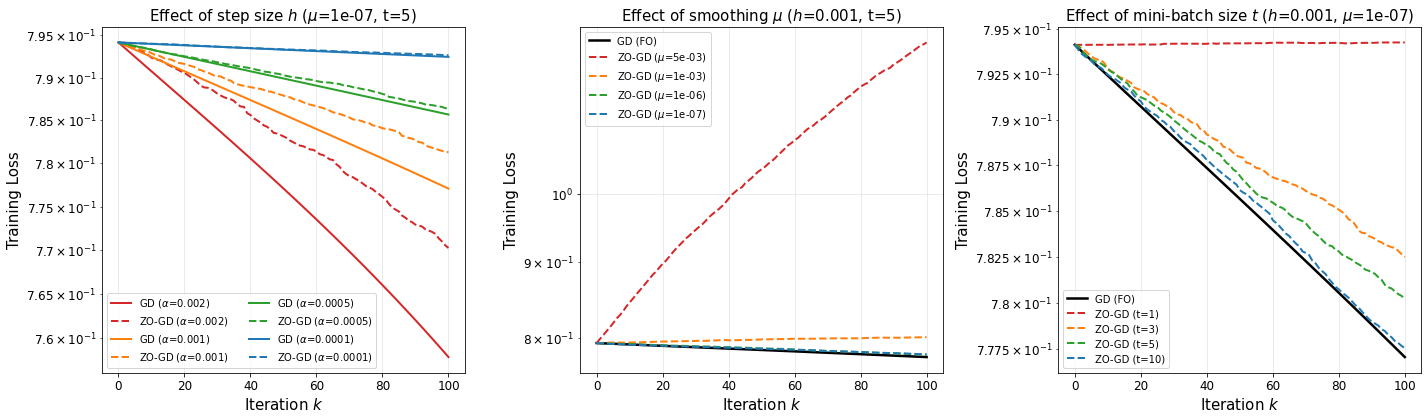

Plot saved: nn_param_sensitivity.pdf


In [36]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
iters_param = np.arange(n_iters_param + 1)
colors = ['tab:red', 'tab:orange', 'tab:green', 'tab:blue']
 
# --- Alpha plot ---
ax = axes[0]
for i, alpha_val in enumerate(alphas):
    r = results_alpha[alpha_val]
    ax.semilogy(iters_param, r['fo'], '-', color=colors[i], linewidth=2,
                label=f'GD ($\\alpha$={alpha_val})')
    ax.semilogy(iters_param, r['zo_mean'], '--', color=colors[i], linewidth=2,
                label=f'ZO-GD ($\\alpha$={alpha_val})')
ax.set_xlabel('Iteration $k$', fontsize=15)
ax.set_ylabel('Training Loss', fontsize=15)
ax.set_title(f'Effect of step size $h$ ($\\mu$={mu_fixed}, t={t_fixed})', fontsize=15)
ax.legend(fontsize=10, ncol=2)
ax.grid(True, alpha=0.3)
 
# --- Mu plot ---
ax = axes[1]
ax.semilogy(iters_param, fo_loss_base, 'k-', linewidth=2.5, label='GD (FO)')
for i, mu_val in enumerate(mus):
    r = results_mu[mu_val]
    ax.semilogy(iters_param, r['zo_mean'], '--', color=colors[i], linewidth=2,
                label=f'ZO-GD ($\\mu$={mu_val:.0e})')
ax.set_xlabel('Iteration $k$', fontsize=15 )
ax.set_ylabel('Training Loss', fontsize=15)
ax.set_title(f'Effect of smoothing $\\mu$ ($h$={alpha_fixed}, t={t_fixed_mu})', fontsize=15)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
 
# --- t plot ---
ax = axes[2]
ax.semilogy(iters_param, fo_loss_base, 'k-', linewidth=2.5, label='GD (FO)')
for i, t_val in enumerate(t_vals):
    r = results_t[t_val]
    ax.semilogy(iters_param, r['zo_mean'], '--', color=colors[i], linewidth=2,
                label=f'ZO-GD (t={t_val})')
ax.set_xlabel('Iteration $k$', fontsize=15)
ax.set_ylabel('Training Loss', fontsize=15)
ax.set_title(f'Effect of mini-batch size $t$ ($h$={alpha_fixed_t}, $\\mu$={mu_fixed_t:.0e})', fontsize=15)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
 
# plt.suptitle(f'Parameter Sensitivity for ZO-GD on Neural Network (n={n_params:,})', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('nn_param_sensitivity.pdf', bbox_inches='tight', dpi=300)
plt.show()
print("Plot saved: nn_param_sensitivity.pdf")

Below we test ZO and FO version of GD for training the Neural netwrok with different dimesnions and number of hidden neurons.

In [18]:
# %% Cell 9: Experiment 3 - Dimension scaling

print("=" * 60)
print("Experiment 3: Dimension scaling")
print("=" * 60)

hidden_dims = [16, 32, 64, 128, 256]
n_iters_dim = 1000
n_zo_runs_dim = 2

# Fixed parameters for all runs
alpha_dim = 5e-4
mu_dim = 1e-8
t_dim = 10
lam_dim = 1e-2

dim_results = {}

for h_val in hidden_dims:
    print(f"\n  h={h_val}...")
    net_h = TwoLayerNet(d=d, h=h_val)
    n_p = net_h.n_params
    print(f"    n_params = {n_p}")
    
    theta0_h = net_h.init_params(scale=0.01)
    
    # FO-GD (timed)
    t0 = time.time()
    _, fo_losses = run_gd(net_h, X_train, y_train, lam_dim, theta0_h, alpha_dim, n_iters_dim)
    fo_time = time.time() - t0
    fo_time_per_run = fo_time
    print(f"    FO-GD: final loss={fo_losses[-1]:.6f}, time={fo_time:.1f}s ({fo_time_per_run:.2f} s)")
    
    # ZO-GD (timed, averaged)
    t0 = time.time()
    zo_all_runs = []
    for run in range(n_zo_runs_dim):
        # np.random.seed(700 + run)
        _, zo_losses = run_gd(net_h, X_train, y_train, lam_dim, theta0_h, alpha_dim, n_iters_dim,
                              zo=True, mu=mu_dim, t=t_dim)
        zo_all_runs.append(zo_losses)
    zo_mean = np.mean(zo_all_runs, axis=0)
    zo_time = time.time() - t0
    zo_time_per_run = zo_time / (n_zo_runs_dim)
    print(f"    ZO-GD: final loss={zo_mean[-1]:.6f}, time={zo_time:.1f}s ({zo_time_per_run:.2f} s)")
    # Compute iterations to reach within 10% of FO final loss
    fo_threshold = fo_losses[-1] + (fo_losses[0]-fo_losses[-1]) * 0.2
    fo_cross = np.where(fo_losses <= fo_threshold)[0]
    fo_iters_to_thresh = fo_cross[0] if len(fo_cross) > 0 else n_iters_dim
    
    zo_cross = np.where(zo_mean <= fo_threshold)[0]
    zo_iters_to_thresh = zo_cross[0] if len(zo_cross) > 0 else n_iters_dim
    
    dim_results[h_val] = {
        'n_params': n_p,
        'fo_losses': fo_losses,
        'zo_mean': zo_mean,
        'zo_all': zo_all_runs,
        'gap': np.abs(zo_mean[-1] - fo_losses[-1]),
        'fo_time_per_iter': fo_time_per_run,
        'zo_time_per_iter': zo_time_per_run,
        'fo_iters_to_thresh': fo_iters_to_thresh,
        'zo_iters_to_thresh': zo_iters_to_thresh,
    }

print("\nDimension scaling runs complete.")

Experiment 3: Dimension scaling

  h=16...
    n_params = 12577
    FO-GD: final loss=0.692169, time=4.7s (4.70 s)
    ZO-GD: final loss=0.691966, time=51.7s (25.86 s)

  h=32...
    n_params = 25153
    FO-GD: final loss=0.671965, time=8.9s (8.93 s)
    ZO-GD: final loss=0.672088, time=87.2s (43.58 s)

  h=64...
    n_params = 50305
    FO-GD: final loss=0.676074, time=15.1s (15.12 s)
    ZO-GD: final loss=0.679766, time=163.2s (81.60 s)

  h=128...
    n_params = 100609
    FO-GD: final loss=0.652901, time=33.0s (32.97 s)
    ZO-GD: final loss=0.658378, time=378.9s (189.46 s)

  h=256...
    n_params = 201217
    FO-GD: final loss=0.686556, time=56.1s (56.13 s)
    ZO-GD: final loss=0.701716, time=504.6s (252.32 s)

Dimension scaling runs complete.


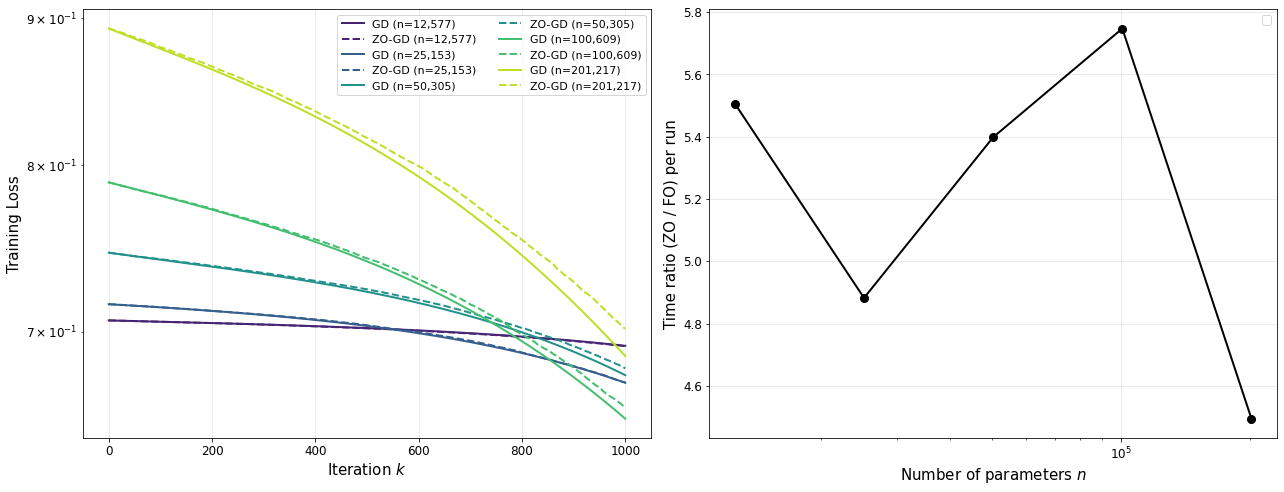

Plot saved: nn_dimension_scaling.pdf


In [33]:
# %% Cell 10: Plot Experiment 3
# font = {'family': 'serif', 'color':  'black', 'weight': 'normal', 'size': 28}
# font1 = {'family': 'serif', 'size': 34}
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
colors_dim = plt.cm.viridis(np.linspace(0.1, 0.9, len(hidden_dims)))

# --- Plot 1: Convergence curves for different dimensions ---
ax = axes[0]
for i, h_val in enumerate(hidden_dims):
    r = dim_results[h_val]
    n_p = r['n_params']
    iters_d = np.arange(len(r['fo_losses']))
    ax.semilogy(iters_d, r['fo_losses'], '-', color=colors_dim[i], linewidth=2,
                label=f'GD (n={n_p:,})')
    ax.semilogy(iters_d, r['zo_mean'], '--', color=colors_dim[i], linewidth=2,
                label=f'ZO-GD (n={n_p:,})')
ax.set_xlabel('Iteration $k$', fontsize=15)
ax.set_ylabel('Training Loss', fontsize=15)
# ax.set_title('Convergence across dimensions', fontsize=15)
ax.legend(fontsize=11, ncol=2)
ax.grid(True, alpha=0.3)

# --- Plot 2: Per-iteration time ratio ZO/FO vs dimension ---
ax = axes[1]
n_params_list = [dim_results[h]['n_params'] for h in hidden_dims]
time_ratios = [dim_results[h]['zo_time_per_iter'] / dim_results[h]['fo_time_per_iter'] 
               for h in hidden_dims]

ax.plot(n_params_list, time_ratios, 'ko-', linewidth=2, markersize=8)
# ax.axhline(y=np.mean(time_ratios), color='r', linestyle='--', linewidth=1.5, 
#            label=f'Mean ratio = {np.mean(time_ratios):.1f}')
ax.set_xlabel('Number of parameters $n$', fontsize=15)
ax.set_ylabel('Time ratio (ZO / FO) per run', fontsize=15)
ax.set_xscale('log')
ax.legend(loc='best', fontsize=12)
ax.grid(True, alpha=0.3)

# plt.suptitle(f'Dimension Scaling ($\\alpha$={alpha_dim}, $\\mu$={mu_dim:.0e}, t={t_dim}, $\\lambda$={lam_dim})',
#              fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('nn_dimension_scaling.pdf', bbox_inches='tight', dpi=300)
plt.show()
print("Plot saved: nn_dimension_scaling.pdf")

In [20]:
# %% Cell 11: Summary statistics table

print("\n" + "=" * 95)
print("SUMMARY TABLE: Dimension Scaling Results")
print("=" * 95)
print(f"{'h':>6} {'n_params':>10} {'FO final':>12} {'ZO final':>12} {'Gap':>12} "
      f"{'FO iters':>9} {'ZO iters':>9} {'ZO/FO':>8} {'Time ZO/FO':>10}")
print("-" * 95)
for h_val in hidden_dims:
    r = dim_results[h_val]
    time_ratio = r['zo_time_per_iter'] / r['fo_time_per_iter']
    fo_it = r['fo_iters_to_thresh']
    zo_it = r['zo_iters_to_thresh']
    iter_ratio = zo_it / fo_it if fo_it > 0 else float('inf')
    print(f"{h_val:>6} {r['n_params']:>10,} {r['fo_losses'][-1]:>12.6f} "
          f"{r['zo_mean'][-1]:>12.6f} {r['gap']:>12.6f} "
          f"{fo_it:>9} {zo_it:>9} {iter_ratio:>8.2f} {time_ratio:>10.1f}")
print("-" * 95)
print(f"\n  Threshold: within 1% of FO final loss for each dimension.")
print(f"  'FO iters' / 'ZO iters': iterations to reach threshold.")
print(f"  'ZO/FO': ratio of ZO to FO iterations (should be ~1 if no curse of dimensionality).")
print(f"  'Time ZO/FO': per-iteration wall-clock time ratio (expected ~{t_dim+1} due to t={t_dim}).")


SUMMARY TABLE: Dimension Scaling Results
     h   n_params     FO final     ZO final          Gap  FO iters  ZO iters    ZO/FO Time ZO/FO
-----------------------------------------------------------------------------------------------
    16     12,577     0.692169     0.691966     0.000203       900       892     0.99        5.5
    32     25,153     0.671965     0.672088     0.000123       902       904     1.00        4.9
    64     50,305     0.676074     0.679766     0.003693       891       918     1.03        5.4
   128    100,609     0.652901     0.658378     0.005478       876       900     1.03        5.7
   256    201,217     0.686556     0.701716     0.015160       861       904     1.05        4.5
-----------------------------------------------------------------------------------------------

  Threshold: within 1% of FO final loss for each dimension.
  'FO iters' / 'ZO iters': iterations to reach threshold.
  'ZO/FO': ratio of ZO to FO iterations (should be ~1 if no curse